In [9]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import utils as ut

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


To validate my code, I run simulations at $T_{\text{BKT}}$ and observe the expected behaviour

$$
S(k)\propto k^{-7/4}
$$,

where $k:=|\vec k|$ is the magnitude of the wavevector and $S(k)$ is the radially-averaged structure factor.

In [10]:
def structure_factor(lattice):
    N = lattice.size

    spin_x = np.cos(lattice)
    spin_y = np.sin(lattice)

    spin_x_k = np.fft.fft2(spin_x)
    spin_y_k = np.fft.fft2(spin_y)

    S_k = (np.abs(spin_x_k)**2 + np.abs(spin_y_k)**2) / N

    return np.fft.fftshift(S_k)

def radial_average(S_k):
    L = S_k.shape[0]

    # wavevector values along each axis
    k = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(L))
    kx, ky = np.meshgrid(k, k)

    # magnitude of wavevector at every pixel
    k_mag = np.sqrt(kx**2 + ky**2)

    # width of one radial bin
    dk = 2 * np.pi / L

    k_values = np.arange(0, np.pi, dk)
    S_radial = []

    for k0 in k_values:
        mask = (k_mag >= k0) & (k_mag < k0 + dk)
        S_radial.append(np.mean(S_k[mask]))

    return k_values, np.array(S_radial)

In [11]:
L = 100 # system is a square lattice of L^2 spins

# hamiltonian parameters
H = 0. # H = mu_s * B / J
phi = 0 # angle of magnetic field
T = 0.8935 # critical temperature T_BKT for this validation

# metropolis parameters
delta = np.pi / 4 # the maximum a spin can rotate in one iteration
num_sweeps = 10000 # number of monte carlo sweeps = num_sweeps * N monte carlo iterations
# 5000 sweeps = ~3 seconds

# validation parameters
runs = 100

In [12]:
N = L**2
steps = N * num_sweeps

S_radials = []

for run in range(runs):
    lattice = ut.generate_lattice(L)
    energy = ut.get_energy(lattice, H, phi)
    final_lattice, _, _, _, _ = ut.metropolis(lattice, steps, T, H, phi, energy, delta)

    S_k = structure_factor(final_lattice)
    k, S_radial = radial_average(S_k)

    S_radials.append(S_radial)

mean_S_radial = np.mean(S_radials, axis=0)

In [34]:
# fit low-k data to a best-fit line and compute its gradient

x = np.log(k[1:])
y = np.log(mean_S_radial[1:]) # [1:] to remove the trivial k=0 point

slope, intercept = np.polyfit(x, y, 1)

print("Gradient =", slope)

Gradient = -1.6940566368363734


/var/folders/b_/h635prgn7r3clgwpkm9x_l_h0000gn/T/ipykernel_66370/2696531222.py:5: RuntimeWarning: divide by zero encountered in power
  fit = np.exp(intercept) * k**slope


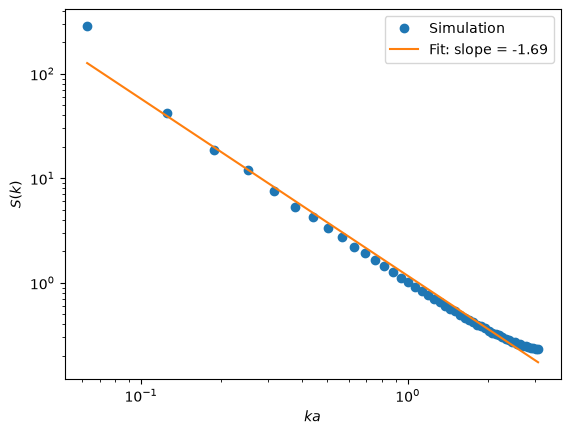

In [35]:
# plot data with best-fit line superimposed

plt.loglog(k[1:], mean_S_radial[1:], 'o', label="Simulation")

fit = np.exp(intercept) * k**slope
plt.loglog(k, fit, label=f"Fit: slope = {slope:.2f}")

plt.xlabel(r"$ka$")
plt.ylabel(r"$S(k)$")
plt.legend()
plt.show()